# Segundo Examen Parcial — Introducción al Machine Learning

**Universidad El Bosque — Programa de Matemáticas y Estadística — 2026-2**

Integrante: Daniel Vargas

Este cuaderno **no redefine** carga de datos, ajuste, riesgo, sensibilidad ni
selección: importa todo desde el paquete `parcial_ml` (`src/parcial_ml/`) y
presenta las salidas y respuestas de los tres ejercicios.

El archivo `validation.csv` se usa **únicamente para evaluar** los modelos,
nunca para ajustarlos.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from parcial_ml.data import cargar_conjunto, cargar_entrenamiento, cargar_validacion
from parcial_ml.analysis import (
    GRADOS_EJ1, GRADOS_COMPARACION,
    recorrer_grados, grado_optimo,
    ajustar_por_conjunto, crear_malla, sensibilidad_por_grado,
    riesgo_validacion_promedio, tabla_seleccion,
)
from parcial_ml.plots import graficar_riesgos, graficar_hipotesis

RESULTADOS = Path('..') / 'resultados'
pd.set_option('display.float_format', lambda v: f'{v:.5f}')

---
# Ejercicio 1 — Complejidad y generalización

Se usa **solo `train_A.csv`** para ajustar polinomios de grado $d=1,\dots,15$;
`validation.csv` solo para evaluar.

## (a) Riesgo de entrenamiento y de validación por grado

In [2]:
x_A, y_A = cargar_conjunto('train_A')
x_val, y_val = cargar_validacion()
print('train_A:', x_A.shape[0], 'observaciones | validation:', x_val.shape[0], 'observaciones')

tabla_ej1 = recorrer_grados(x_A, y_A, x_val, y_val, GRADOS_EJ1)
tabla_ej1.rename(columns={'riesgo_train': 'riesgo de entrenamiento',
                          'riesgo_val': 'riesgo de validación'})

train_A: 30 observaciones | validation: 140 observaciones


,grado,riesgo de entrenamiento,riesgo de validación
0,1,0.40678,0.51043
1,2,0.32756,0.44105
2,3,0.12041,0.20003
3,4,0.11825,0.20197
4,5,0.08343,0.16140
5,6,0.08298,0.16407
6,7,0.07447,0.18427
7,8,0.06964,0.18982
8,9,0.06918,0.18841
9,10,0.06583,0.22243


## (b) Riesgo de entrenamiento y de validación en función del grado

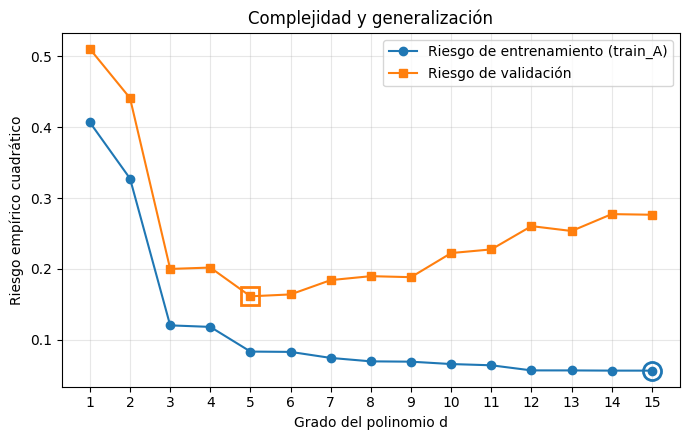

In [3]:
d_train, r_train_min = grado_optimo(tabla_ej1, 'riesgo_train')
d_val, r_val_min = grado_optimo(tabla_ej1, 'riesgo_val')

fig = graficar_riesgos(tabla_ej1, grado_train=d_train, grado_val=d_val,
                       ruta=RESULTADOS / 'ej1_riesgo_vs_grado.png')
plt.show()

## (c) Grados que minimizan cada riesgo

$$d_{\text{train}}=\arg\min_d \hat R_{\text{train}}(d),\qquad d_{\text{val}}=\arg\min_d \hat R_{\text{val}}(d).$$

In [4]:
riesgo_val_en_d_train = tabla_ej1.loc[tabla_ej1.grado == d_train, 'riesgo_val'].iloc[0]
riesgo_train_en_d_val = tabla_ej1.loc[tabla_ej1.grado == d_val, 'riesgo_train'].iloc[0]

print(f'd_train = {d_train}  ->  R_train = {r_train_min:.5f}   (R_val en ese grado = {riesgo_val_en_d_train:.5f})')
print(f'd_val   = {d_val}   ->  R_val   = {r_val_min:.5f}   (R_train en ese grado = {riesgo_train_en_d_val:.5f})')

d_train = 15  ->  R_train = 0.05654   (R_val en ese grado = 0.27648)
d_val   = 5   ->  R_val   = 0.16140   (R_train en ese grado = 0.08343)


**Respuesta (c).** $d_{\text{train}}=15$ (riesgo de entrenamiento $\approx 0.0565$) y
$d_{\text{val}}=5$ (riesgo de validación $\approx 0.1614$).

El riesgo de entrenamiento es no creciente en $d$ (cada modelo contiene al anterior), por lo que el
mínimo siempre cae en el grado máximo. El de validación, en cambio, baja hasta $d=5$–$6$ y luego
sube: más complejidad deja de generalizar mejor.

## (d) Subajuste, mejor balance y sobreajuste entre los grados 2, 6 y 15

Se asocia cada categoría exactamente una vez, mirando los dos riesgos de cada grado:

In [5]:
sel_ej1 = tabla_ej1[tabla_ej1.grado.isin(GRADOS_COMPARACION)].set_index('grado')
asociacion_ej1 = pd.Series({2: 'subajuste', 6: 'mejor balance', 15: 'sobreajuste'}, name='categoría')
resumen_1d = sel_ej1.join(asociacion_ej1)
resumen_1d['brecha (val − train)'] = resumen_1d['riesgo_val'] - resumen_1d['riesgo_train']
resumen_1d.rename(columns={'riesgo_train': 'riesgo de entrenamiento', 'riesgo_val': 'riesgo de validación'})

,riesgo de entrenamiento,riesgo de validación,categoría,brecha (val − train)
grado,,,,
2,0.32756,0.44105,subajuste,0.11349
6,0.08298,0.16407,mejor balance,0.08110
15,0.05654,0.27648,sobreajuste,0.21994


**Respuesta (d).**

| Grado | Categoría | Riesgo entrenamiento | Riesgo validación | Justificación |
|---|---|---|---|---|
| 2 | **Subajuste** | 0.3276 | 0.4411 | Ambos riesgos son altos: el modelo es demasiado simple y no captura la forma de los datos, ni siquiera en la muestra con la que se ajustó. |
| 6 | **Mejor balance** | 0.0830 | 0.1641 | Menor riesgo de validación de los tres, con un riesgo de entrenamiento bajo y una brecha moderada. |
| 15 | **Sobreajuste** | 0.0565 | 0.2765 | Tiene el menor riesgo de entrenamiento pero un riesgo de validación mucho mayor que el de $d=6$: memoriza ruido de la muestra y generaliza peor. |

---
# Ejercicio 2 — Sensibilidad a la muestra

Ahora se usan los tres conjuntos `train_A`, `train_B`, `train_C` y los grados
$d\in\{2,6,15\}$. Para cada grado se ajusta un modelo con cada muestra:
$\hat h_{A,d},\ \hat h_{B,d},\ \hat h_{C,d}$.

In [6]:
entrenamiento = cargar_entrenamiento()
nombres = list(entrenamiento)            # ['train_A', 'train_B', 'train_C']
modelos = ajustar_por_conjunto(entrenamiento, GRADOS_COMPARACION)

print('Modelos ajustados:', sorted(modelos.keys()))

Modelos ajustados: [('train_A', 2), ('train_A', 6), ('train_A', 15), ('train_B', 2), ('train_B', 6), ('train_B', 15), ('train_C', 2), ('train_C', 6), ('train_C', 15)]


## (a) Las tres hipótesis aprendidas, una figura por grado

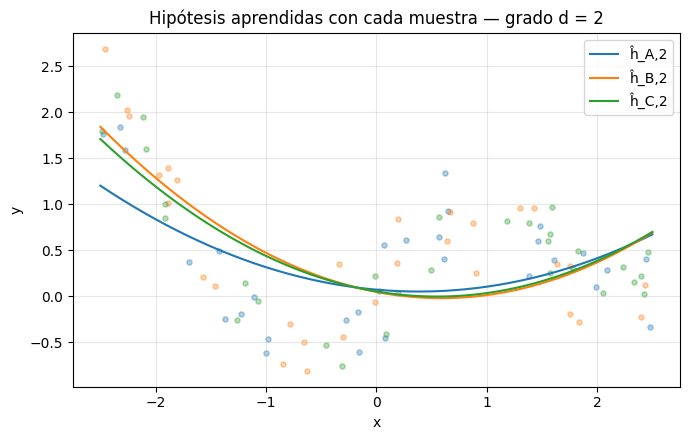

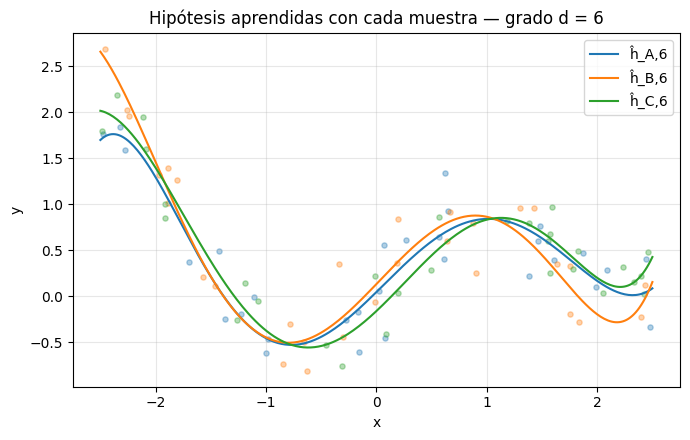

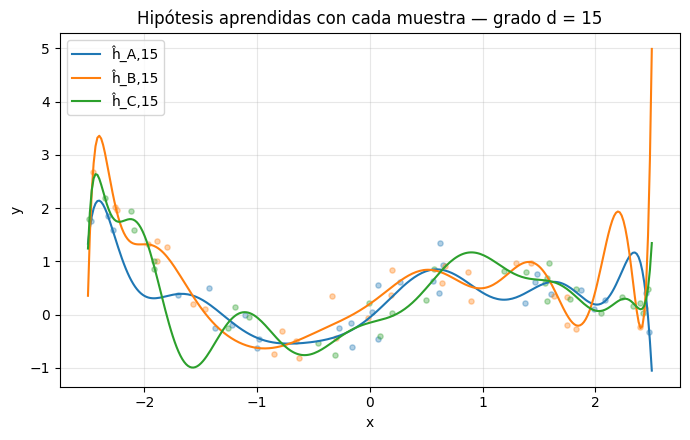

In [7]:
malla = crear_malla(m=300, inferior=-2.5, superior=2.5)
sens = sensibilidad_por_grado(modelos, nombres, GRADOS_COMPARACION, malla)

for d in GRADOS_COMPARACION:
    graficar_hipotesis(d, malla, sens[d]['predicciones'], nombres,
                       entrenamiento=entrenamiento,
                       ruta=RESULTADOS / f'ej2_hipotesis_d{d}.png')
    plt.show()

## (b) Hipótesis media $\bar h_d$ y varianza $V_d$ en la malla común

Malla de $m=300$ puntos igualmente espaciados en $[-2.5,\,2.5]$:

$$\bar h_d(x_j)=\tfrac13\sum_{S\in\{A,B,C\}}\hat h_{S,d}(x_j),\qquad
V_d=\frac1m\sum_{j=1}^{m}\frac13\sum_{S\in\{A,B,C\}}\bigl(\hat h_{S,d}(x_j)-\bar h_d(x_j)\bigr)^2 .$$

In [8]:
print('Tamaño de la malla:', malla.size, '| extremos:', malla[0], malla[-1])
for d in GRADOS_COMPARACION:
    print(f'V_{d:<2d} = {sens[d]["V"]:.6f}')

Tamaño de la malla: 300 | extremos: -2.5 2.5
V_2  = 0.009695
V_6  = 0.014151
V_15 = 0.128793


## (c) Orden de menor a mayor $V_d$

In [9]:
V = {d: sens[d]['V'] for d in GRADOS_COMPARACION}
orden = sorted(V, key=V.get)
mas_estable, mas_sensible = orden[0], orden[-1]

print('Orden de menor a mayor V_d:', ' < '.join(f'V_{d}' for d in orden))
print('Más estable :', mas_estable, f'(V = {V[mas_estable]:.6f})')
print('Más sensible:', mas_sensible, f'(V = {V[mas_sensible]:.6f})')
print(f'V_15 / V_6 = {V[15]/V[6]:.1f}   |   V_15 / V_2 = {V[15]/V[2]:.1f}')

Orden de menor a mayor V_d: V_2 < V_6 < V_15
Más estable : 2 (V = 0.009695)
Más sensible: 15 (V = 0.128793)
V_15 / V_6 = 9.1   |   V_15 / V_2 = 13.3


**Respuesta (c).** $V_2 < V_6 < V_{15}$. El modelo **más estable** es el de grado
**2** y el **más sensible** al cambio de muestra es el de grado **15**
($V_{15}\approx 0.129$, unas 9 veces el de $d=6$ y más de 13 veces el de $d=2$): sus tres curvas
difieren mucho entre sí, sobre todo hacia los extremos de la malla (ver figuras de (a)).

## (d) Alto sesgo, balance sesgo–varianza y alta varianza

Para cada grado se reporta $V_d$ y el riesgo de validación promedio
$R_{\text{val}}(d)=\frac13\sum_S\hat R_{\text{validation}}(\hat h_{S,d})$:

In [10]:
asociacion_ej2 = {2: 'alto sesgo', 6: 'balance sesgo–varianza', 15: 'alta varianza'}
filas = []
for d in GRADOS_COMPARACION:
    r_prom, _ = riesgo_validacion_promedio(modelos, nombres, d, x_val, y_val)
    filas.append({'grado': d, 'categoría': asociacion_ej2[d], 'V_d': V[d], 'R_val promedio': r_prom})
pd.DataFrame(filas).set_index('grado')

,categoría,V_d,R_val promedio
grado,,,
2,alto sesgo,0.00969,0.45892
6,balance sesgo–varianza,0.01415,0.16484
15,alta varianza,0.12879,0.31782


**Respuesta (d).**

| Grado | Categoría | $V_d$ | Riesgo promedio de validación | Justificación |
|---|---|---|---|---|
| 2 | **Alto sesgo** | 0.0097 | 0.4589 | Casi no cambia con la muestra (varianza mínima) pero su error de validación es el más alto: el error viene de un modelo demasiado rígido, no de la muestra. |
| 6 | **Balance sesgo–varianza** | 0.0142 | 0.1648 | Varianza baja y el menor riesgo de validación de los tres. |
| 15 | **Alta varianza** | 0.1288 | 0.3178 | Varianza más de 9 veces la de $d=6$: cambia mucho de muestra a muestra y eso deteriora su riesgo de validación. |

---
# Ejercicio 3 — Selección del modelo

## (a) Tabla de $R_{\text{val}}(d)$ y $V_d$

In [11]:
tabla_ej3 = tabla_seleccion(modelos, nombres, GRADOS_COMPARACION, x_val, y_val, sens)
tabla_ej3.set_index('grado').rename(columns={'R_val': 'R_val(d)', 'V_d': 'V_d'})

,R_val(d),V_d
grado,,
2,0.45892,0.00969
6,0.16484,0.01415
15,0.31782,0.12879


## (b) Grado seleccionado

In [12]:
t = tabla_ej3.set_index('grado')
print(t)
print()
print('Grado con menor R_val :', int(t.R_val.idxmin()), f'(R_val = {t.R_val.min():.5f})')
print('Grado con menor V_d   :', int(t.V_d.idxmin()), f'(V_d = {t.V_d.min():.6f})')

        R_val     V_d
grado                
2     0.45892 0.00969
6     0.16484 0.01415
15    0.31782 0.12879

Grado con menor R_val : 6 (R_val = 0.16484)
Grado con menor V_d   : 2 (V_d = 0.009695)


**Respuesta (b).** Se selecciona **$d=6$**.

Los dos valores de la tabla que sustentan la selección son:

* $R_{\text{val}}(6)\approx 0.1648$, el **menor** riesgo de validación de los tres (menos de la mitad que $d=2$, $0.4589$, y alrededor de la mitad que $d=15$, $0.3178$);
* $V_6\approx 0.0142$, una sensibilidad a la muestra muy baja: apenas un poco mayor que la de $d=2$ ($0.0097$) y unas 9 veces menor que la de $d=15$ ($0.1288$).

El grado 2 es algo más estable, pero su riesgo de validación es casi 3 veces el de $d=6$;
el grado 15 es el más inestable y además generaliza peor. $d=6$ es el mejor comportamiento conjunto.

## (c) ¿Coincide el grado seleccionado con el de menor riesgo de entrenamiento en `train_A`?

In [13]:
d_seleccionado = int(t.R_val.idxmin())
print('Grado seleccionado                         :', d_seleccionado)
print('Grado de menor riesgo de entrenamiento (A) :', d_train, f'(R_train = {r_train_min:.5f})')
print('¿Coinciden?', 'sí' if d_seleccionado == d_train else 'no')

Grado seleccionado                         : 6
Grado de menor riesgo de entrenamiento (A) : 15 (R_train = 0.05654)
¿Coinciden? no


**Respuesta (c).** **No.** El grado seleccionado es $d=6$, mientras que el grado que
produce el menor riesgo de entrenamiento en `train_A.csv` es $d_{\text{train}}=15$
(riesgo $\approx 0.0565$). Minimizar el riesgo de entrenamiento no equivale a elegir el mejor modelo
para datos nuevos.

## (d) Afirmación: «el grado de mayor complejidad debe preferirse porque alcanza el menor riesgo de entrenamiento»

In [14]:
r_train_6  = tabla_ej1.loc[tabla_ej1.grado == 6,  'riesgo_train'].iloc[0]
r_train_15 = tabla_ej1.loc[tabla_ej1.grado == 15, 'riesgo_train'].iloc[0]
r_val_6, r_val_15 = t.loc[6, 'R_val'], t.loc[15, 'R_val']

print(f'Entrenamiento (train_A): R_train(15) = {r_train_15:.5f}  <  R_train(6) = {r_train_6:.5f}   -> d=15 gana en entrenamiento')
print(f'Validación (promedio)  : R_val(15)   = {r_val_15:.5f}  >  R_val(6)   = {r_val_6:.5f}   -> d=15 pierde en validación')

Entrenamiento (train_A): R_train(15) = 0.05654  <  R_train(6) = 0.08298   -> d=15 gana en entrenamiento
Validación (promedio)  : R_val(15)   = 0.31782  >  R_val(6)   = 0.16484   -> d=15 pierde en validación


**Respuesta (d).** **No**, la afirmación **no es compatible** con los resultados.

Es cierto que el grado 15 alcanza el menor riesgo de entrenamiento
($\hat R_{\text{train}}(15)\approx 0.0565<\hat R_{\text{train}}(6)\approx 0.0830$), pero ese es justo
el síntoma del sobreajuste. El par de valores que decide la respuesta es

$$R_{\text{val}}(15)\approx 0.3178 \;>\; R_{\text{val}}(6)\approx 0.1648,$$

es decir, con muestras nuevas el modelo de grado 15 tiene aproximadamente el **doble** de riesgo que el
de grado 6, además de ser unas 9 veces más sensible a la muestra ($V_{15}\approx0.129$ frente a
$V_6\approx0.014$). Preferir el modelo más complejo por su riesgo de entrenamiento lleva a elegir un
modelo que generaliza peor.